# Which stations are full and free at the same times?

Step 1: a matrix with one row per snapshot (about one per minute) and one column per station, holding the
**share of free docks** docks / (bikes + docks), then the correlation between every pair of columns.

## 1. Load

In [10]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

DATA = Path("data_1")
TZ = "Europe/Paris"
pd.set_option("display.width", 160)

snap = pd.read_csv(DATA / "snapshots.csv", usecols=["src_ts", "station_id", "bikes", "docks"])
names = pd.read_csv(DATA / "stations.csv", encoding="utf-8").set_index("station_id")["name"]
snap = snap[snap.bikes + snap.docks > 0]  # drop offline snapshots (0 bikes and 0 docks)
print(f"{len(snap):,} rows, {snap.station_id.nunique()} stations")

2,506,022 rows, 1516 stations


## 2. Correlation of the share of free docks

share = docks / (bikes + docks): 0 = full, 1 = empty. Dividing by bikes + docks puts every station on the same 0–1 scale,
whatever its size.

How to read the correlation r of two stations:
- **close to +1:** they are nearly full at the same times and free at the same times
- **close to 0:** one station's share says nothing about the other's
- **close to −1:** when one is nearly full, the other is nearly empty

In [11]:
share = snap.assign(share=snap.docks / (snap.bikes + snap.docks)).pivot(index="src_ts", columns="station_id", values="share")
share = share.dropna(axis=1)                         # keep stations seen in every snapshot
share = share.loc[:, (share.diff().iloc[1:] != 0).sum() >= 30]  # and that change at least 30 times
print(f"matrix: {share.shape[0]} snapshots × {share.shape[1]} stations")

R = share.corr()  # correlation matrix, stations × stations
R = R.rename_axis(index="id A", columns="id B")
pairs = R.where(np.triu(np.ones(R.shape, bool), k=1)).stack().dropna().rename("r").reset_index()  # each pair once
pairs["station A"] = pairs["id A"].map(names)
pairs["station B"] = pairs["id B"].map(names)
pairs = pairs.sort_values("r")
print(f"{len(pairs):,} pairs, median r = {pairs.r.median():.2f}")

cols = ["r", "station A", "station B", "id A", "id B"]
print("\nhighest correlation:")
display(pairs.tail(10)[::-1][cols].round(3))
print("about zero correlation:")
display(pairs[pairs.r.abs() < 0.02].sample(10, random_state=0)[cols].round(3))
print("most negative correlation:")
display(pairs.head(10)[cols].round(3))

matrix: 1654 snapshots × 1413 stations
997,578 pairs, median r = 0.04

highest correlation:


,r,station A,station B,id A,id B
469265,0.995,François 1er - Montaigne,Vincent Auriol - Louise Weiss,66505511,567884788
875143,0.994,Bara - Henri Farman,Madeleine Vionnet,434419150,2515855808
146222,0.993,Laffitte - Italiens,Bara - Henri Farman,27363323,434419150
427541,0.993,Georges V - François 1er,Quai du Président Roosevelt - Pont Aval,60667075,1057335613
903586,0.993,Vincent Auriol - Louise Weiss,Vivienne - Petits Champs,567884788,20458224375
266313,0.993,Berri - Haussmann,François 1er - Montaigne,39296638,66505511
322925,0.993,Artois - Berri,Président Roosevelt - Rouget de Lisle,49474389,16379269732
266907,0.992,Berri - Haussmann,Vincent Auriol - Louise Weiss,39296638,567884788
427688,0.992,Georges V - François 1er,Président Roosevelt - Rouget de Lisle,60667075,16379269732
427630,0.992,Georges V - François 1er,Madeleine Vionnet,60667075,2515855808


about zero correlation:


,r,station A,station B,id A,id B
89702,-0.012,Charles Delescluze,Marché Saint-Quentin,15299574,15309045
420,-0.004,Ventadour - Opéra,Saint-Séverin - Saint-Michel,6245,82335295
454718,-0.019,Daumesnil - Hébrard,Ledru-Rollin - Charonne,66491395,426772876
66045,0.019,Arsonval - Falguière,Porte Dorée,11375742,220502135
26084,0.011,Bassano - Iéna,Eugène Oudiné - Dessous Des Berges,7304,256561528
780917,0.004,Grenelle - Violet,Senard - Charles Blum,213684750,392576677
624298,0.014,Saint-Jacques - Tombe Issoire,Boulets - Voltaire,101490103,478952881
181884,0.012,Bobillot - Paulin Mery,Suffren - Pérignon,27415150,82448637
336481,0.008,Saint-Gilles - Turenne,Lucie Aubrac - Fort,54000537,596872103
533310,0.014,Volontaires - Lecourbe,Gabriel Péri - Place de la Libération,82457375,16930981813


most negative correlation:


,r,station A,station B,id A,id B
735291,-0.985,Place Jean-Spire-Lemaître,François Truffaut - Saint Emilion,129164969,267976590
318427,-0.985,Commandant Rivière,Bobillot - Tolbiac,49403716,54000578
554803,-0.984,Place Lafayette,Guichet - Jean Jaurès,82584215,406806401
442882,-0.984,Guy Môquet - Compoint,Colisée - Champs-Elysées,66491382,121086415
480437,-0.984,Pierre Charron - Champs-Elysées,Guichet - Jean Jaurès,74805344,406806401
870710,-0.984,Guichet - Jean Jaurès,Président Roosevelt - Rouget de Lisle,406806401,16379269732
103296,-0.984,Versailles - Claude Terrasse,Commandant Rivière,15401095,49403716
870436,-0.983,Guichet - Jean Jaurès,Tremblay - Lac des Minimes,406806401,653073004
765477,-0.983,Chemin Vert - Saint-Maur,François Truffaut - Saint Emilion,210744286,267976590
870563,-0.983,Guichet - Jean Jaurès,Quai du Président Roosevelt - Pont Aval,406806401,1057335613


One example of each: the two stations' share of free docks over time.

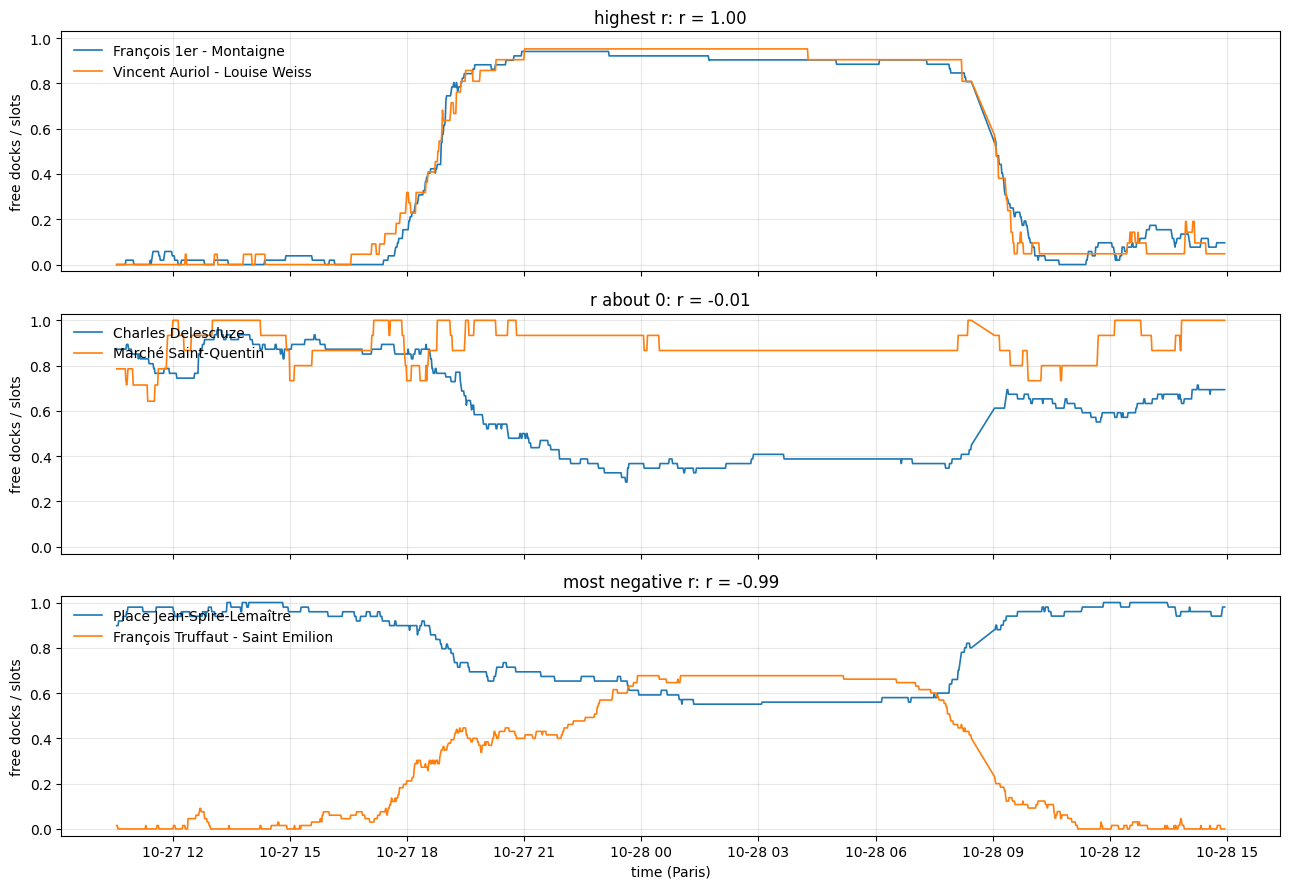

In [12]:
time = pd.to_datetime(share.index, unit="s", utc=True).tz_convert(TZ)
examples = {
    "highest r": pairs.iloc[-1],
    "r about 0": pairs[pairs.r.abs() < 0.02].sample(1, random_state=0).iloc[0],
    "most negative r": pairs.iloc[0],
}
fig, axes = plt.subplots(3, 1, figsize=(13, 9), sharex=True)
for ax, (title, row) in zip(axes, examples.items()):
    for sid, color in ((row["id A"], "tab:blue"), (row["id B"], "tab:orange")):
        ax.plot(time, share[sid], color=color, lw=1.2, label=names.get(sid, sid))
    ax.set(ylim=(-0.03, 1.03), ylabel="free docks / slots", title=f"{title}: r = {row.r:.2f}")
    ax.grid(alpha=0.3)
    ax.legend(loc="upper left", frameon=False)
axes[-1].set_xlabel("time (Paris)")
plt.tight_layout()
plt.show()

## 3. Hierarchical clustering

Distance between two stations: d = 1 − r (0 = identical curves, 1 = unrelated, 2 = mirror images). Start with every
station alone, then repeatedly merge the two closest groups, where the distance between two groups is the **average**
distance between their stations (average linkage). The merges form a tree (dendrogram).

Cut the tree at height 1 − `MIN_R`: two groups are only merged if their stations correlate on average by at least
`MIN_R`. The cut decides the number of clusters and their sizes, instead of choosing them by hand. Groups smaller than
`MIN_SIZE` stations are left in no cluster.

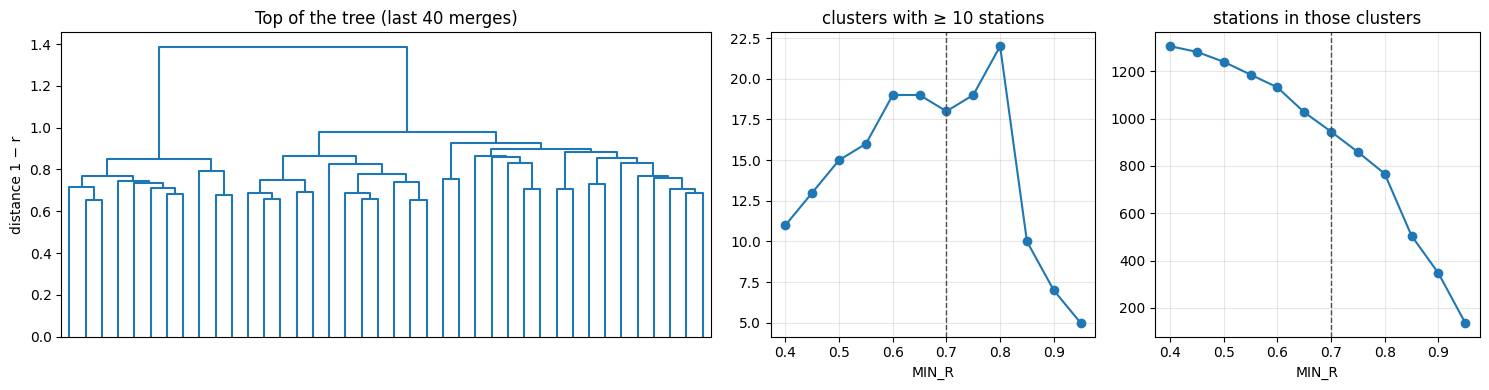

321 groups at the cut; 18 with at least 10 stations, holding 945 of 1413 stations


,stations,mean r within,first stations
cluster,,,
H1,361,0.81,"Pontoise - La Tournelle, Gare du Nord - Saint-Vincent de Paul, Hautpoul - Jean Jaurès, Porte de Ménilmontant"
H2,228,0.85,"Ventadour - Opéra, Mairie du 2ème, Marché aux fleurs, Rougemont - Poissonnière"
H3,81,0.78,"Chernoviz - Raynouard, Colonel Monteil - Brune, Charles Delescluze, Mozart - Jasmin"
H4,26,0.80,"Siam - La Pompe, Geoffroy-Saint-Hilaire - Saint-Marcel, Ivry - Baudricourt, Bineau - Louise Michel"
H5,24,0.79,"Colonel Pierre Avia, Flandrin - Longchamp, Square Claude Bernard, Liège - Moscou"
H6,23,0.79,"Pont de Lodi - Dauphine, Nationale - Vincent Auriol, Suffren - La Motte-Piquet, Hameau Fleuri - Marché"
H7,23,0.77,"Jean-Baptiste Pigalle - La Bruyere, Seine - Flandre, Gambetta - Père Lachaise, Sorbier - Ménilmontant"
H8,20,0.81,"Victor Hugo - La Pompe, Ouest - Château , Charonne - Alexandre Dumas, Frères Flavien - Porte des Lilas"
H9,20,0.80,"Crevaux - Bugeaud, Jean Bologne - Passy, Place d'Italie - Soeur Rosalie, Gare de Lyon - Place Louis Armand"


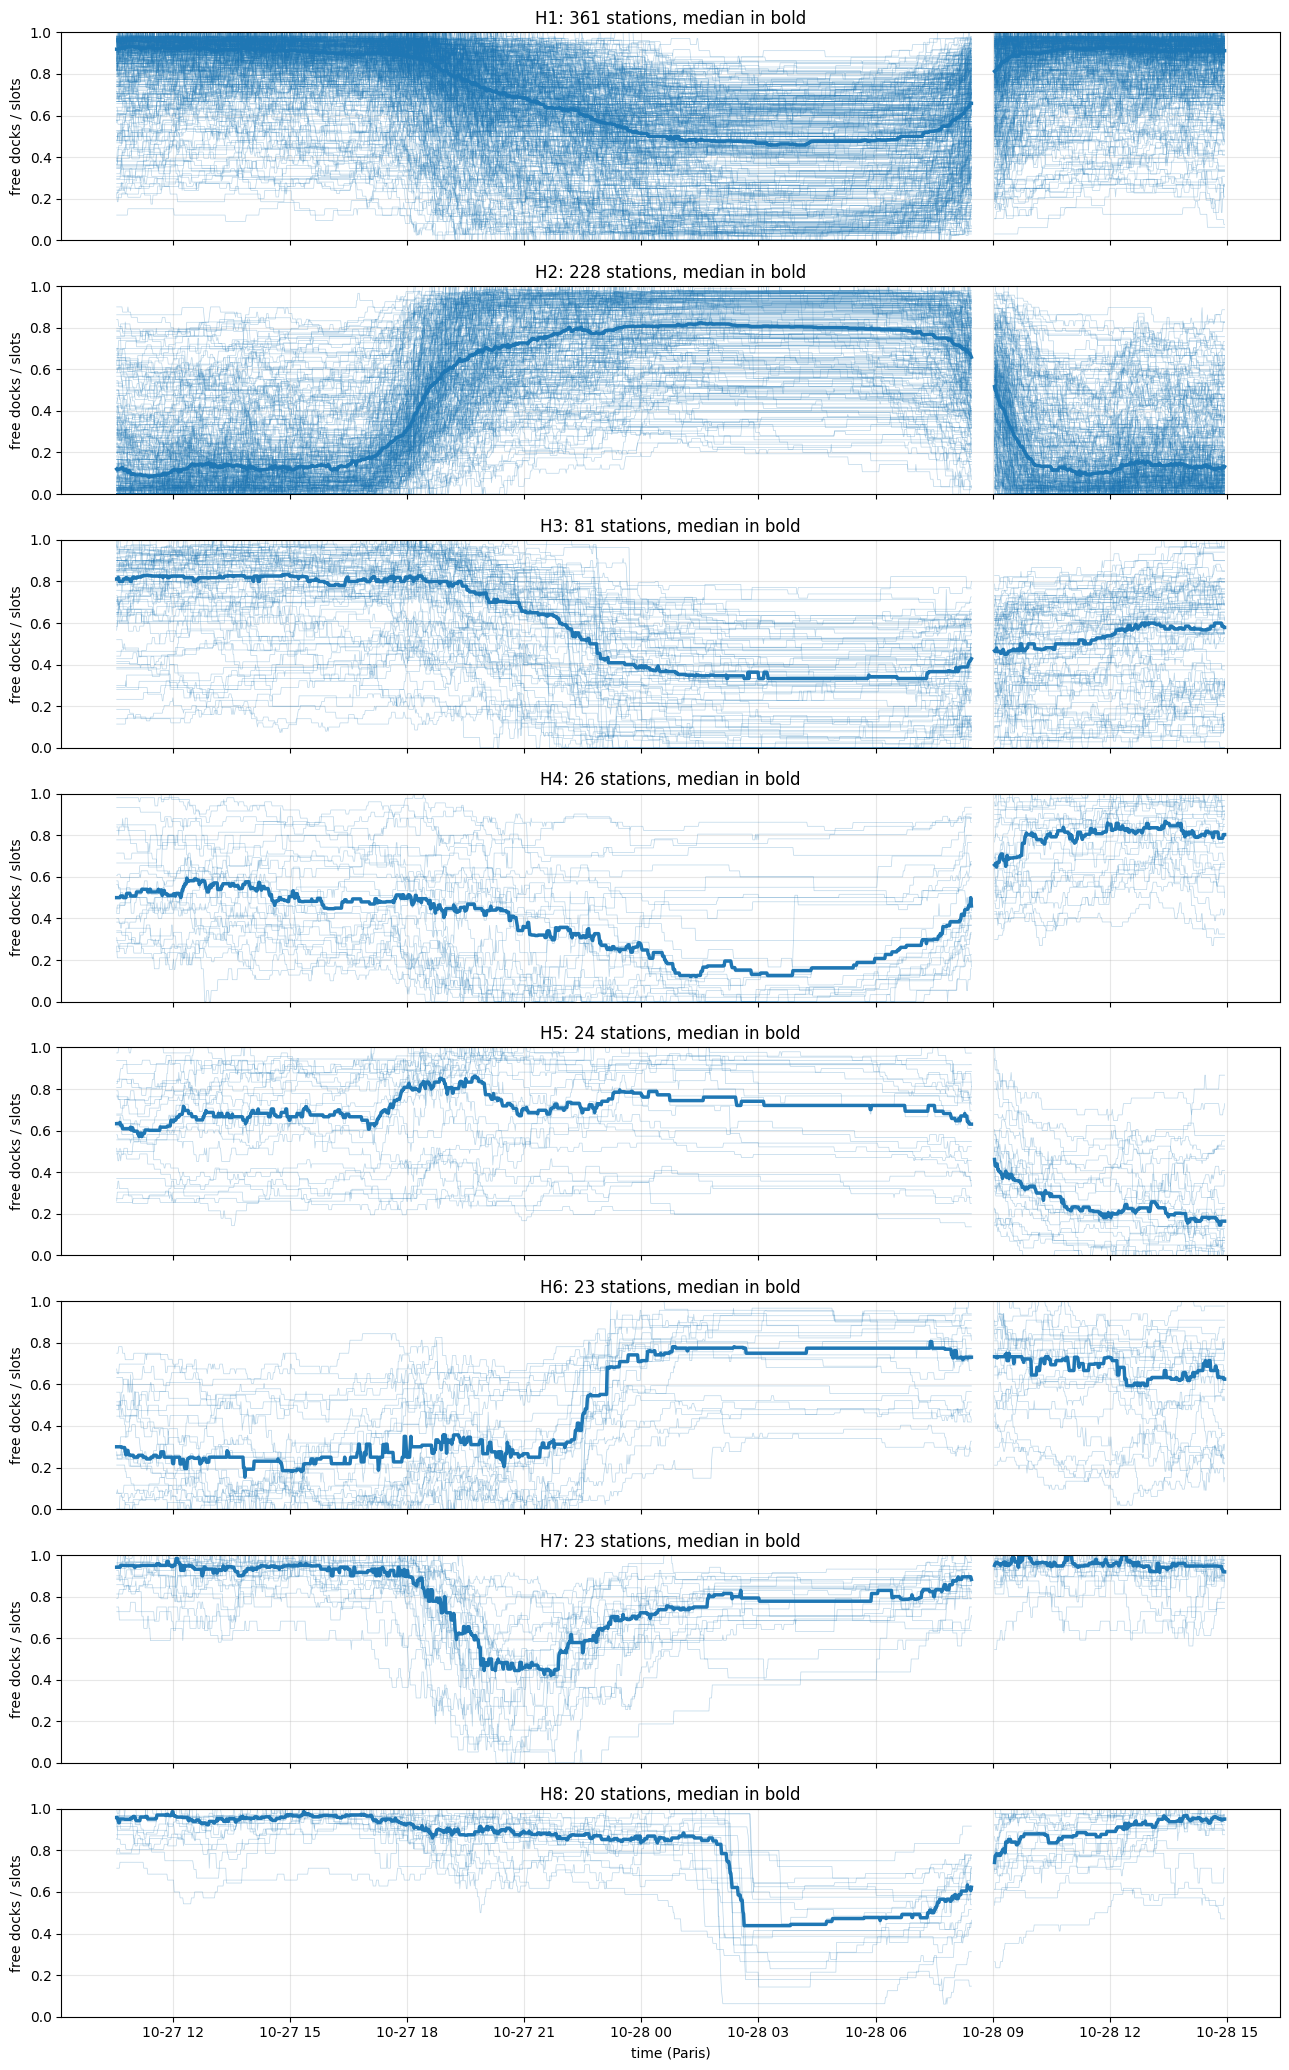

In [13]:
from scipy.cluster.hierarchy import dendrogram, fcluster, linkage
from scipy.spatial.distance import squareform

MIN_R = 0.7     # cut: groups whose stations correlate on average less than this are not merged
MIN_SIZE = 10   # smaller groups are left in no cluster
N_SHOW = 8      # clusters drawn (the largest)

D = (1 - R.to_numpy()).clip(min=0)  # clip: rounding can give -1e-16 on the diagonal
np.fill_diagonal(D, 0)
tree = linkage(squareform(D, checks=False), method="average")

fig, (ax1, ax2, ax3) = plt.subplots(1, 3, figsize=(15, 4), gridspec_kw={"width_ratios": [2, 1, 1]})
dendrogram(tree, truncate_mode="lastp", p=40, no_labels=True, color_threshold=0, above_threshold_color="tab:blue", ax=ax1)
ax1.set(ylabel="distance 1 − r", title="Top of the tree (last 40 merges)")
# how the choice of MIN_R changes the result
grid = np.round(np.arange(0.4, 0.96, 0.05), 2)
n_clusters, n_stations = [], []
for r_cut in grid:
    s = pd.Series(fcluster(tree, t=1 - r_cut, criterion="distance")).value_counts()
    n_clusters.append((s >= MIN_SIZE).sum())
    n_stations.append(s[s >= MIN_SIZE].sum())
for ax, y, title in ((ax2, n_clusters, f"clusters with ≥ {MIN_SIZE} stations"), (ax3, n_stations, "stations in those clusters")):
    ax.plot(grid, y, marker="o", color="tab:blue")
    ax.axvline(MIN_R, color="0.3", ls="--", lw=1)  # current choice
    ax.set(xlabel="MIN_R", title=title)
    ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

label = pd.Series(fcluster(tree, t=1 - MIN_R, criterion="distance"), index=R.index.rename("station_id"))
sizes = label.value_counts()
kept = sizes[sizes >= MIN_SIZE].index  # largest first
hclusters = {f"H{i + 1}": list(label.index[label == c]) for i, c in enumerate(kept)}
print(f"{len(sizes)} groups at the cut; {len(hclusters)} with at least {MIN_SIZE} stations, holding "
      f"{sum(map(len, hclusters.values()))} of {len(label)} stations")

rows = []
for name, members in hclusters.items():
    within = R.loc[members, members].to_numpy()[np.triu_indices(len(members), 1)].mean()
    rows.append({"cluster": name, "stations": len(members), "mean r within": round(within, 2),
                 "first stations": ", ".join(names.get(s, str(s)) for s in members[:4])})
with pd.option_context("display.max_colwidth", None):
    display(pd.DataFrame(rows).set_index("cluster"))

# a row of NaN just before the first snapshot after a data gap, so the lines break instead of crossing the gap
after_gap = pd.Series(time).diff().gt(pd.Timedelta("5min")).to_numpy()
breaks = pd.DataFrame(np.nan, index=time[after_gap] - pd.Timedelta("1s"), columns=share.columns)
by_time = pd.concat([share.set_axis(time), breaks]).sort_index()

shown = list(hclusters)[:N_SHOW]
fig, axes = plt.subplots(len(shown), 1, figsize=(13, 2.6 * len(shown)), sharex=True)
for ax, name in zip(np.atleast_1d(axes), shown):
    members = hclusters[name]
    ax.plot(by_time.index, by_time[members].to_numpy(), color="tab:blue", lw=0.5, alpha=0.3)
    ax.plot(by_time.index, by_time[members].median(axis=1), color="tab:blue", lw=2.5)
    ax.set(ylim=(0, 1), ylabel="free docks / slots", title=f"{name}: {len(members)} stations, median in bold")
    ax.grid(alpha=0.3)
ax.set_xlabel("time (Paris)")
plt.tight_layout()
plt.show()

The original data: number of free docks of every station, one panel per cluster.

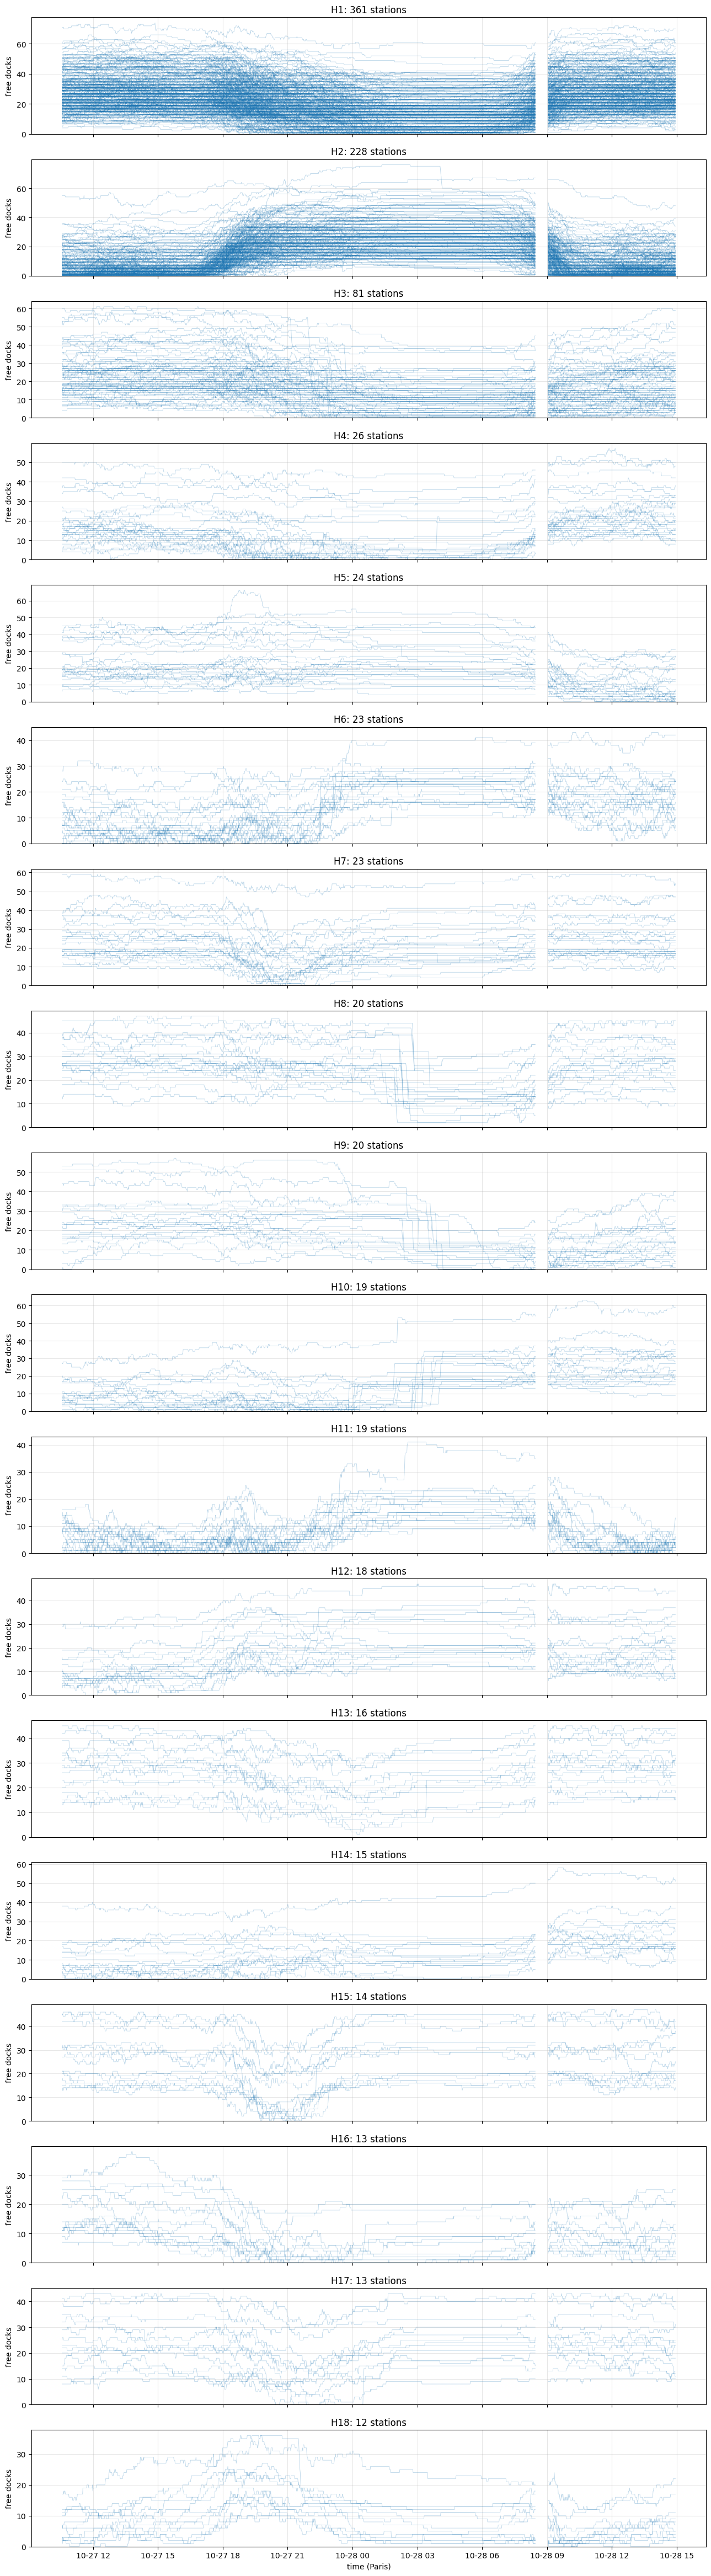

In [14]:
docks = snap.pivot(index="src_ts", columns="station_id", values="docks").loc[share.index, share.columns]
docks_by_time = pd.concat([docks.set_axis(time), breaks]).sort_index()  # same NaN rows at the data gap as by_time

fig, axes = plt.subplots(len(hclusters), 1, figsize=(13, 2.6 * len(hclusters)), sharex=True)
for ax, (name, members) in zip(np.atleast_1d(axes), hclusters.items()):
    ax.plot(docks_by_time.index, docks_by_time[members].to_numpy(), color="tab:blue", lw=0.6, alpha=0.3)
    ax.set(ylim=(0, None), ylabel="free docks", title=f"{name}: {len(members)} stations")
    ax.grid(alpha=0.3)
ax.set_xlabel("time (Paris)")
plt.tight_layout()
plt.show()